In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd



In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, classification_report, confusion_matrix,ConfusionMatrixDisplay)

In [ ]:
SEED = 42

In [ ]:
df = pd.read_excel('Dry_Bean_Dataset.xlsx')
df.to_csv('Dry_Bean_Dataset.csv', index=False, encoding='utf-8')

In [ ]:
X = df.drop(columns="Class")    # les 16 variables
y = df["Class"]                 # la variété
 
print("Dimensions :", df.shape)
print("\nValeurs manquantes :", df.isna().sum().sum())
print("\nDescription des 16 variables :")
print(X.describe().T)

Dimensions : (13611, 17)

Valeurs manquantes : 0

Description des 16 variables :
                   count          mean           std           min  \
Area             13611.0  53048.284549  29324.095717  20420.000000   
Perimeter        13611.0    855.283459    214.289696    524.736000   
MajorAxisLength  13611.0    320.141867     85.694186    183.601165   
MinorAxisLength  13611.0    202.270714     44.970091    122.512653   
AspectRation     13611.0      1.583242      0.246678      1.024868   
Eccentricity     13611.0      0.750895      0.092002      0.218951   
ConvexArea       13611.0  53768.200206  29774.915817  20684.000000   
EquivDiameter    13611.0    253.064220     59.177120    161.243764   
Extent           13611.0      0.749733      0.049086      0.555315   
Solidity         13611.0      0.987143      0.004660      0.919246   
roundness        13611.0      0.873282      0.059520      0.489618   
Compactness      13611.0      0.799864      0.061713      0.640577   
ShapeFact

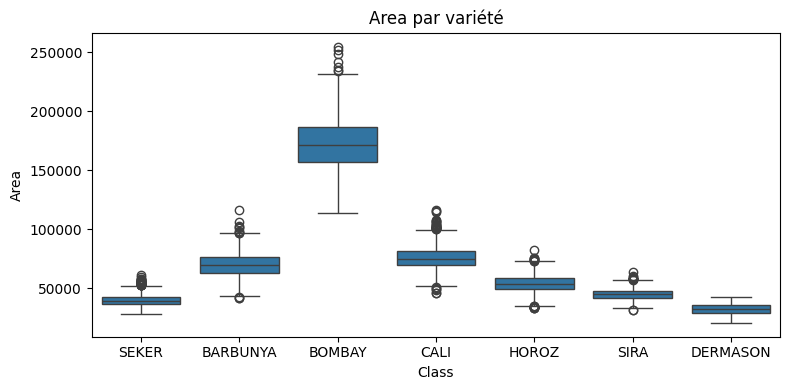

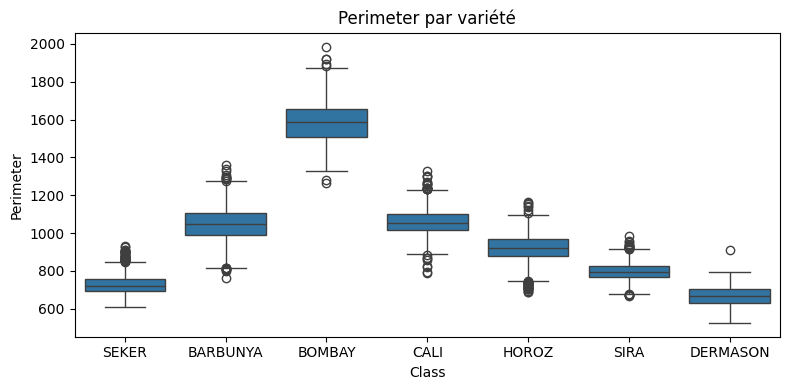

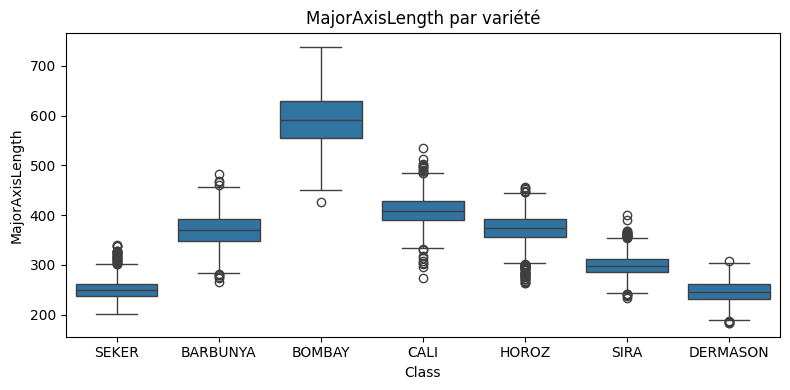

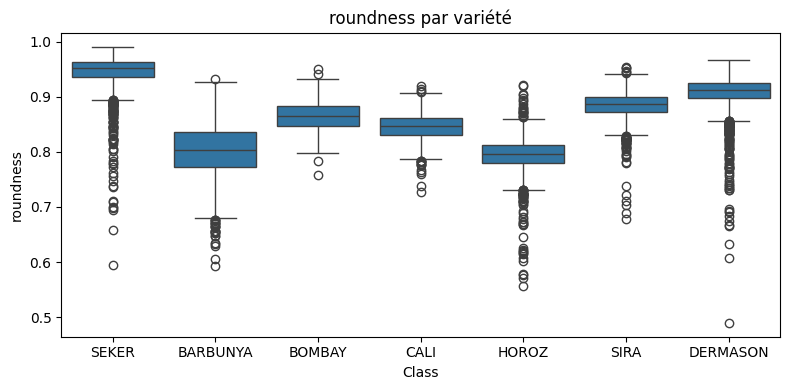

In [ ]:
for col in ["Area", "Perimeter", "MajorAxisLength", "roundness"]:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df, x="Class", y=col)
    plt.title(f"{col} par variété")
    plt.tight_layout()
    plt.show()

C:\Users\moham\AppData\Local\Temp\ipykernel_20596\1797456181.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


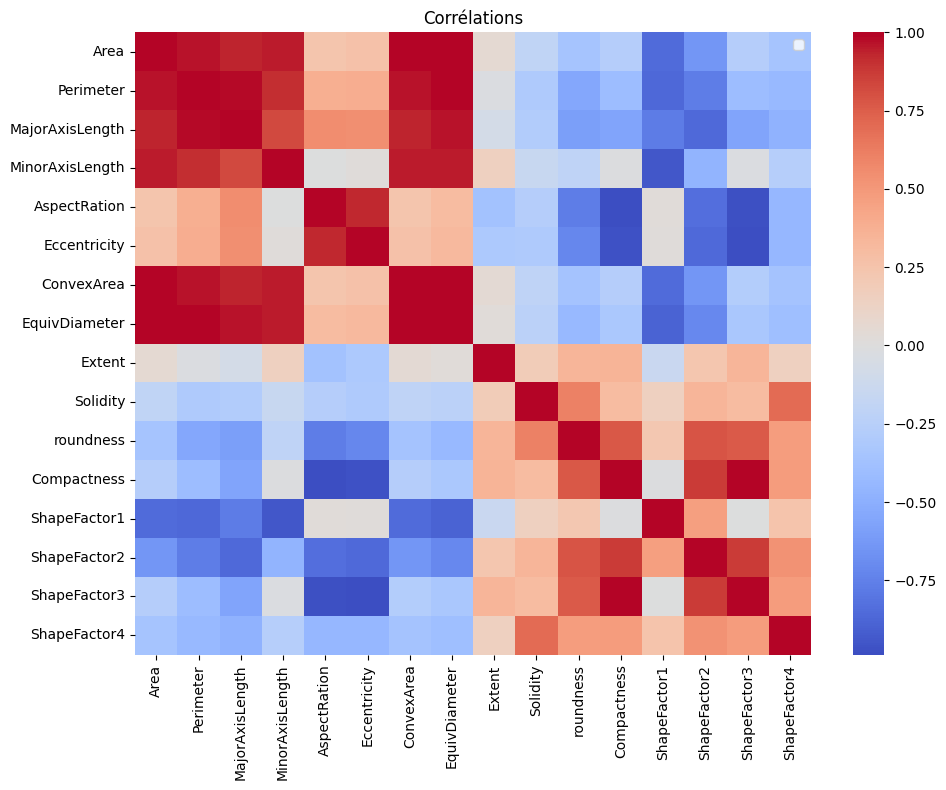

In [ ]:
# 3.3 Corrélations entre variables
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), cmap="coolwarm", center=0)
plt.title("Corrélations")
plt.tight_layout()
plt.legend()
plt.show()

In [ ]:
# 4. Séparation stratifiée 80 % / 20 %
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"the training phase shape is : {X_test.shape} and testing phase shape is : {X_test.shape}")

the training phase shape is : (2723, 16) and testing phase shape is : (2723, 16)


In [ ]:
modeles = {
    "Régression logistique": (
        Pipeline([("scaler", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=5000))]),
        {"clf__C": [0.1, 1, 10, 100]}),
}

In [ ]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000)),
])

In [ ]:
# 6. Recherche de C par validation croisée (sur le train)
grille = {"clf__C": [0.01, 0.1, 1, 10, 100]}
gs = GridSearchCV(pipe, grille, cv=5, scoring="f1_macro")
gs.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=5000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fold and candidat

In [ ]:
print("Meilleur C :", gs.best_params_)
print("F1 macro (CV) :", round(gs.best_score_, 4))

Meilleur C : {'clf__C': 100}
F1 macro (CV) : 0.937


In [ ]:
y_pred = gs.best_estimator_.predict(X_test)

In [ ]:
print("Accuracy        :", round(accuracy_score(y_test, y_pred), 4))
print("Précision macro :", round(precision_score(y_test, y_pred, average="macro"), 4))
print("Rappel macro    :", round(recall_score(y_test, y_pred, average="macro"), 4))
print("F1 macro        :", round(f1_score(y_test, y_pred, average="macro"), 4))
print()
print(classification_report(y_test, y_pred, digits=4))   # métriques par classe

Accuracy        : 0.921
Précision macro : 0.9354
Rappel macro    : 0.9309
F1 macro        : 0.9329

              precision    recall  f1-score   support

    BARBUNYA     0.9518    0.8943    0.9222       265
      BOMBAY     1.0000    0.9904    0.9952       104
        CALI     0.9275    0.9417    0.9346       326
    DERMASON     0.9226    0.9083    0.9154       709
       HOROZ     0.9656    0.9456    0.9555       386
       SEKER     0.9349    0.9557    0.9452       406
        SIRA     0.8452    0.8805    0.8625       527

    accuracy                         0.9210      2723
   macro avg     0.9354    0.9309    0.9329      2723
weighted avg     0.9219    0.9210    0.9213      2723



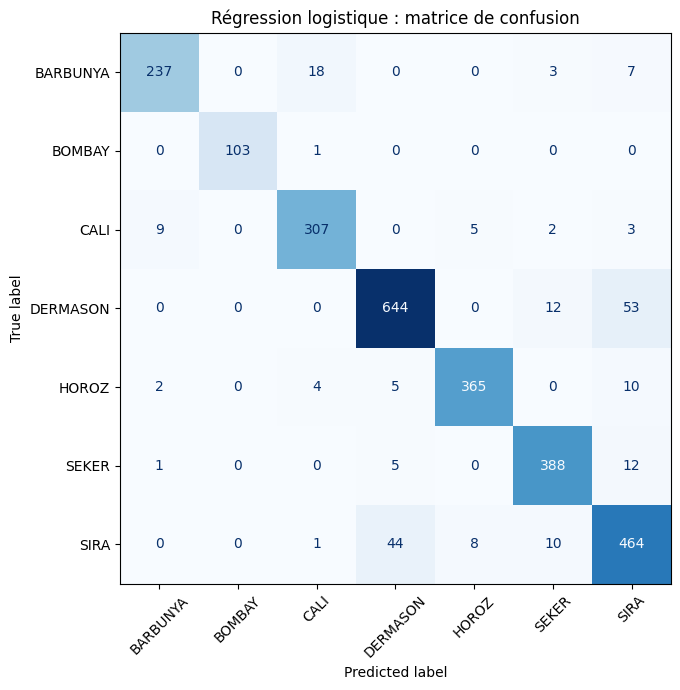

In [ ]:
#  8. Matrice de confusion (7 x 7)
classes = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=classes)
 
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("Régression logistique : matrice de confusion")
plt.tight_layout()
plt.show()